Using Colab cache for faster access to the 'vehicle-classification-dataset' dataset.
Path to dataset files: /kaggle/input/vehicle-classification-dataset

Folder structure:
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/SUV -> 10 files, e.g. 89.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/BUS -> 10 files, e.g. 10.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/Truck -> 10 files, e.g. 97.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/MPV -> 10 files, e.g. 56.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/Sedan -> 10 files, e.g. 76.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/Hatchback -> 10 files, e.g. 45.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/Pickup -> 10 files, e.g. 67.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/Easy-Bike -> 10 files, e.g. 30.jpg
/kaggle/input/vehicle-classification-dataset/Vehicle Test Data/CNG -> 10 

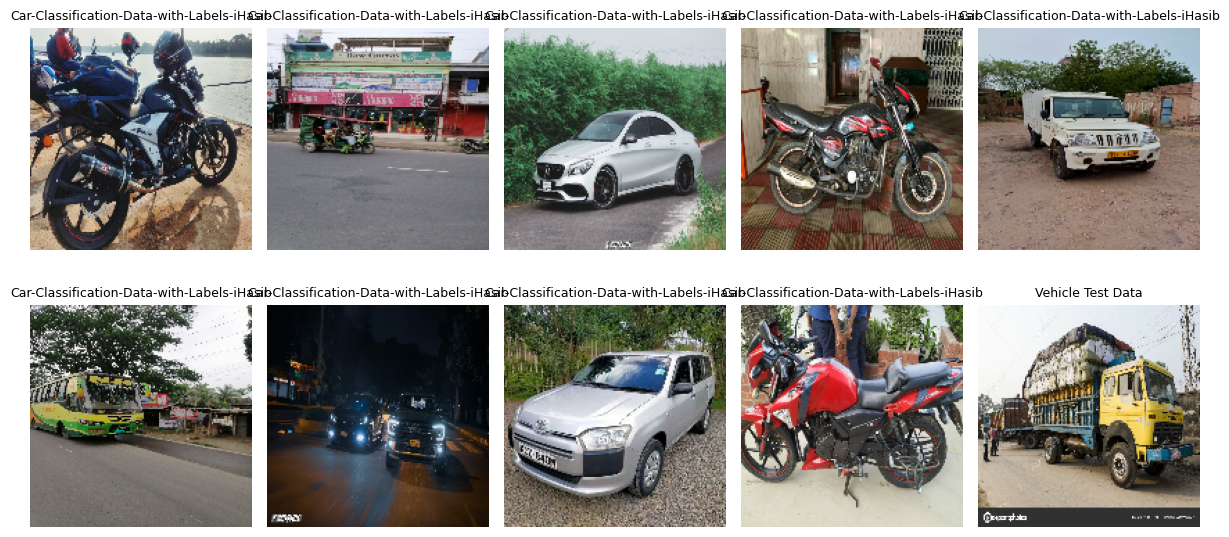

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VehicleClassifier_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,722 (9.24 MB)

 Trainable params: 164,482 (642.51 KB)

 Non-trainable params: 2,258,240 (8.61 MB)


=== Phase 1: Training classifier head (frozen pretrained base) ===
Epoch 1/15
  1/165 ━━━━━━━━━━━━━━━━━━━━ 27:38 10s/step - accuracy: 0.5938 - loss: 0.9242

In [ ]:
# ============================================
# Vehicle Type Classification using Transfer Learning
# Pretrained backbone: MobileNetV2 (ImageNet weights)
#
# Dataset: ilhamhasib/vehicle-classification-dataset (Kaggle)
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and inspect structure
# ----------------------------------------------------

path = kagglehub.dataset_download("ilhamhasib/vehicle-classification-dataset")
print("Path to dataset files:", path)

# Walk the full tree upfront so we don't have to guess folder names blind
print("\nFolder structure:")
for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files, e.g.", files[0])

# UPDATE THIS once you see the real structure printed above.
# Most Kaggle image-classification datasets are laid out as:
#   <path>/<split>/<class_name>/*.jpg   or   <path>/<class_name>/*.jpg
DATA_DIR = path   # <-- update to the folder that directly contains class subfolders

IMG_SIZE = (160, 160)   # MobileNetV2's native/efficient input size
BATCH_SIZE = 32

# ----------------------------------------------------
# STEP 2: Load Dataset (auto train/val split since no separate folders confirmed yet)
# ----------------------------------------------------
# If the printed structure above shows pre-split train/ and test/ (or valid/)
# folders, replace this block with two separate image_dataset_from_directory
# calls pointing at each folder instead (see the "PRE-SPLIT" note below).

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="validation",
    seed=42
)

# PRE-SPLIT NOTE (use instead of the block above if train/test folders exist):
# train_ds = tf.keras.utils.image_dataset_from_directory(
#     os.path.join(DATA_DIR, "train"), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
# val_ds = tf.keras.utils.image_dataset_from_directory(
#     os.path.join(DATA_DIR, "test"), image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

class_names = train_ds.class_names
num_classes = len(class_names)
print("\nNumber of classes:", num_classes)
print("Classes:", class_names)

# ----------------------------------------------------
# STEP 3: Visualize Sample Images
# ----------------------------------------------------

plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(min(10, len(images))):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 4: Preprocess - Augment + MobileNetV2-specific preprocessing
# ----------------------------------------------------

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# MobileNetV2 expects inputs scaled to [-1, 1], not [0, 1]
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_prepped = prepare(train_ds, training=True)
val_ds_prepped = prepare(val_ds, training=False)

# ----------------------------------------------------
# STEP 5: Build model with PRETRAINED MobileNetV2 base
# ----------------------------------------------------

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False   # freeze pretrained weights initially

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs, name="VehicleClassifier_MobileNetV2")
model.summary()

# ----------------------------------------------------
# STEP 6: Phase 1 - Train classifier head only (base frozen)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

print("\n=== Phase 1: Training classifier head (frozen pretrained base) ===")
history1 = model.fit(
    train_ds_prepped,
    epochs=15,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 7: Phase 2 - Fine-tune top layers of the pretrained base
# ----------------------------------------------------

base_model.trainable = True

# Only unfreeze the last ~30 layers, keep earlier (more generic) layers frozen
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # much lower LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n=== Phase 2: Fine-tuning top layers of pretrained base ===")
history2 = model.fit(
    train_ds_prepped,
    epochs=10,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 8: Evaluate
# ----------------------------------------------------

val_loss, val_acc = model.evaluate(val_ds_prepped)
print(f"\nValidation Accuracy: {val_acc*100:.2f}%")

# ----------------------------------------------------
# STEP 9: Plot combined training history (both phases)
# ----------------------------------------------------

def merge_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(merge_history(history1, history2, 'accuracy'), label='Train Accuracy')
plt.plot(merge_history(history1, history2, 'val_accuracy'), label='Val Accuracy')
plt.axvline(x=len(history1.history['accuracy']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(merge_history(history1, history2, 'loss'), label='Train Loss')
plt.plot(merge_history(history1, history2, 'val_loss'), label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 10: Confusion Matrix & Classification Report
# ----------------------------------------------------

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([y.numpy() for x, y in val_ds_prepped], axis=0)
y_pred_probs = model.predict(val_ds_prepped)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(8, num_classes * 0.6), max(6, num_classes * 0.5)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

# ----------------------------------------------------
# STEP 11: Predict on a Single New Vehicle Image
# ----------------------------------------------------

def predict_vehicle(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    img_array = preprocess_input(img_array)
    prediction = model.predict(img_array)
    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100
    print(f"Predicted: {predicted_class} ({confidence:.2f}% confidence)")
    return predicted_class, confidence

# Example usage:
# predict_vehicle("/path/to/some/vehicle.jpg")

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('vehicle_classification_mobilenetv2.keras')
print("Model saved successfully!")

In [1]:
# ============================================
# Vehicle Type Classification using Transfer Learning
# Pretrained backbone: EfficientNetV2B0 (ImageNet weights)
#
# Dataset: ilhamhasib/vehicle-classification-dataset (Kaggle)
# Balanced subset: 250 images per class
# ============================================

import os
import random
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
import kagglehub

# ----------------------------------------------------
# STEP 1: Download dataset from Kaggle and inspect structure
# ----------------------------------------------------

path = kagglehub.dataset_download("ilhamhasib/vehicle-classification-dataset")
print("Path to dataset files:", path)

print("\nFolder structure:")
for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files, e.g.", files[0])

# UPDATE THIS if the printed structure shows class folders nested deeper
# (e.g. path/train/<class_name>/*.jpg instead of path/<class_name>/*.jpg)
SOURCE_DIR = path

# ----------------------------------------------------
# STEP 1b: Build a balanced subset — max 250 images per class
# ----------------------------------------------------

IMAGES_PER_CLASS = 250
BALANCED_DIR = "/content/vehicle_balanced"   # change if not on Colab, e.g. "./vehicle_balanced"

if os.path.exists(BALANCED_DIR):
    shutil.rmtree(BALANCED_DIR)
os.makedirs(BALANCED_DIR)

valid_ext = (".jpg", ".jpeg", ".png", ".bmp")

print("\nBuilding balanced subset...")
for class_name in sorted(os.listdir(SOURCE_DIR)):
    class_path = os.path.join(SOURCE_DIR, class_name)
    if not os.path.isdir(class_path):
        continue

    images = [f for f in os.listdir(class_path) if f.lower().endswith(valid_ext)]
    random.seed(42)
    random.shuffle(images)
    selected = images[:IMAGES_PER_CLASS]

    dest_class_path = os.path.join(BALANCED_DIR, class_name)
    os.makedirs(dest_class_path, exist_ok=True)

    for img_name in selected:
        shutil.copy(
            os.path.join(class_path, img_name),
            os.path.join(dest_class_path, img_name)
        )

    print(f"  {class_name}: copied {len(selected)} / {len(images)} available images")

DATA_DIR = BALANCED_DIR   # everything below reads from the balanced folder

IMG_SIZE = (224, 224)     # EfficientNetV2B0's native input size
BATCH_SIZE = 32

# ----------------------------------------------------
# STEP 2: Load Dataset (auto train/val split)
# ----------------------------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="training",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    validation_split=0.2,
    subset="validation",
    seed=42
)

class_names = train_ds.class_names
num_classes = len(class_names)
print("\nNumber of classes:", num_classes)
print("Classes:", class_names)

# ----------------------------------------------------
# STEP 3: Visualize Sample Images
# ----------------------------------------------------

plt.figure(figsize=(12, 6))
for images, labels in train_ds.take(1):
    for i in range(min(10, len(images))):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]], fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 4: Preprocess - Augment + EfficientNetV2-specific preprocessing
# ----------------------------------------------------

data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# EfficientNetV2's preprocess_input is a no-op (normalization is baked into
# the model itself), but we keep the call for consistency / future-proofing.
preprocess_input = tf.keras.applications.efficientnet_v2.preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_prepped = prepare(train_ds, training=True)
val_ds_prepped = prepare(val_ds, training=False)

# ----------------------------------------------------
# STEP 5: Build model with PRETRAINED EfficientNetV2B0 base
# ----------------------------------------------------

base_model = tf.keras.applications.EfficientNetV2B0(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False   # freeze pretrained weights initially

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs, name="VehicleClassifier_EfficientNetV2B0")
model.summary()

# ----------------------------------------------------
# STEP 6: Phase 1 - Train classifier head only (base frozen)
# ----------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
)

print("\n=== Phase 1: Training classifier head (frozen pretrained base) ===")
history1 = model.fit(
    train_ds_prepped,
    epochs=15,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 7: Phase 2 - Fine-tune top layers of the pretrained base
# ----------------------------------------------------

base_model.trainable = True

# Only unfreeze the last ~30 layers, keep earlier (more generic) layers frozen
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # much lower LR for fine-tuning
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n=== Phase 2: Fine-tuning top layers of pretrained base ===")
history2 = model.fit(
    train_ds_prepped,
    epochs=10,
    validation_data=val_ds_prepped,
    callbacks=[early_stop, reduce_lr]
)

# ----------------------------------------------------
# STEP 8: Evaluate
# ----------------------------------------------------

val_loss, val_acc = model.evaluate(val_ds_prepped)
print(f"\nValidation Accuracy: {val_acc*100:.2f}%")

# ----------------------------------------------------
# STEP 9: Plot combined training history (both phases)
# ----------------------------------------------------

def merge_history(h1, h2, key):
    return h1.history[key] + h2.history[key]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(merge_history(history1, history2, 'accuracy'), label='Train Accuracy')
plt.plot(merge_history(history1, history2, 'val_accuracy'), label='Val Accuracy')
plt.axvline(x=len(history1.history['accuracy']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Accuracy over Epochs')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(merge_history(history1, history2, 'loss'), label='Train Loss')
plt.plot(merge_history(history1, history2, 'val_loss'), label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--')
plt.title('Loss over Epochs')
plt.legend()

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# STEP 10: Confusion Matrix & Classification Report
# ----------------------------------------------------

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([y.numpy() for x, y in val_ds_prepped], axis=0)
y_pred_probs = model.predict(val_ds_prepped)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(max(8, num_classes * 0.6), max(6, num_classes * 0.5)))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

# ----------------------------------------------------
# STEP 11: Predict on a Single New Vehicle Image
# ----------------------------------------------------

def predict_vehicle(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0)
    img_array = preprocess_input(img_array)
    prediction = model.predict(img_array)
    predicted_class = class_names[np.argmax(prediction)]
    confidence = np.max(prediction) * 100
    print(f"Predicted: {predicted_class} ({confidence:.2f}% confidence)")
    return predicted_class, confidence

# Example usage:
# predict_vehicle("/path/to/some/vehicle.jpg")

# ----------------------------------------------------
# STEP 12: Save the Model
# ----------------------------------------------------

model.save('vehicle_classification_efficientnetv2b0.keras')
print("Model saved successfully!")

100%|██████████| 4.38G/4.38G [00:54<00:00, 86.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3

Folder structure:
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/Sedan -> 10 files, e.g. 70.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/Bike -> 10 files, e.g. 5.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/SUV -> 10 files, e.g. 83.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/Easy-Bike -> 10 files, e.g. 39.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/CNG -> 10 files, e.g. 20.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-dataset/versions/3/Vehicle Test Data/Pickup -> 10 files, e.g. 64.jpg
/root/.cache/kagglehub/datasets/ilhamhasib/vehicle-classification-data

ValueError: No images found in directory /content/vehicle_balanced. Allowed formats: ('.bmp', '.gif', '.jpeg', '.jpg', '.png')